In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json

import matplotlib.pyplot as plt
import numpy as np
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design()  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## stacked-bar-chart

**Figure 4: Distribution of failures in MAST-Data with MAST labels over 210 traces, the first 30 traces of each of 7 multi-agent systems.** Each panel is one failure category, titled with its share of all 601 failures; each bar is one system, stacked by the category's failure modes, with counts written in segments large enough to hold them; as tasks and benchmarks differ across systems, the bars show system-specific failure profiles rather than a performance comparison. System design issues are the largest share (41.8%), and ChatDev and MetaGPT, which use explicit verifiers, have the fewest failures in total (41 and 55, against 143 for HyperAgent).

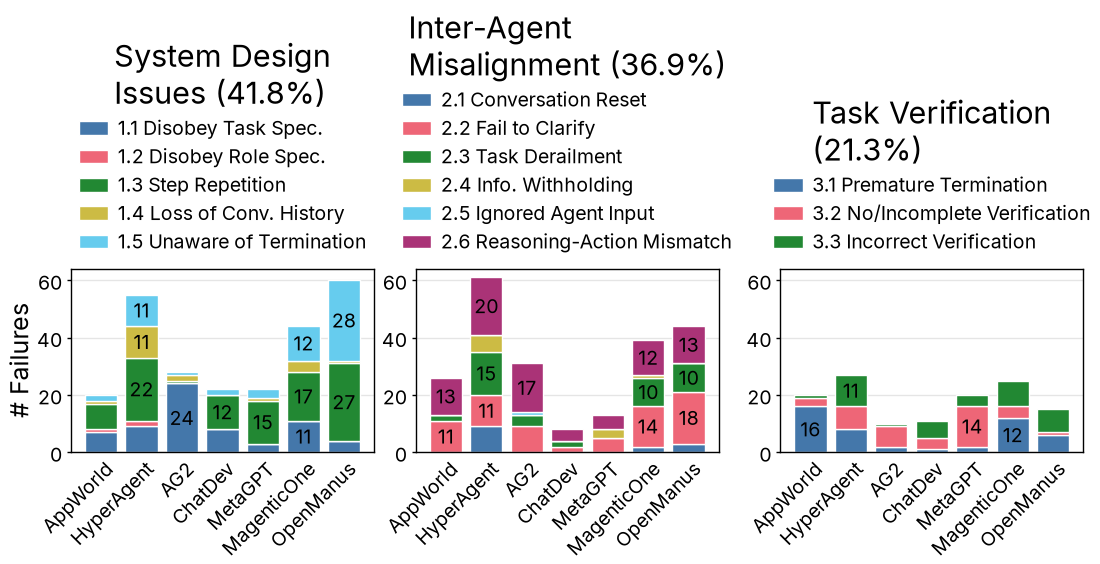

In [2]:
with open("../stacked-bar-chart.json") as f:
    data = json.load(f)

systems = data["systems"]
counts = data["failure_counts"]
x = np.arange(len(systems))
series = [colors[f"series-{i}"] for i in range(1, 7)]
titles = {
    "FC1": "System Design\nIssues (41.8%)",
    "FC2": "Inter-Agent\nMisalignment (36.9%)",
    "FC3": "Task Verification\n(21.3%)",
}
short_names = {
    "1.1": "Disobey Task Spec.",
    "1.2": "Disobey Role Spec.",
    "1.3": "Step Repetition",
    "1.4": "Loss of Conv. History",
    "1.5": "Unaware of Termination",
    "2.1": "Conversation Reset",
    "2.2": "Fail to Clarify",
    "2.3": "Task Derailment",
    "2.4": "Info. Withholding",
    "2.5": "Ignored Agent Input",
    "2.6": "Reasoning-Action Mismatch",
    "3.1": "Premature Termination",
    "3.2": "No/Incomplete Verification",
    "3.3": "Incorrect Verification",
}

fig, axes = plt.subplots(1, 3, figsize=(5.5, 3), sharey=True)
for ax, (category_id, category) in zip(axes, data["failure_categories"].items()):
    below = np.zeros(len(systems))
    for color, mode_id in zip(series, category["modes"]):
        values = np.array([counts[system][mode_id] for system in systems])
        bars = ax.bar(x, values, bottom=below, color=color, edgecolor="white", linewidth=0.5,
                      label=f"{mode_id} {short_names[mode_id]}")
        ax.bar_label(bars, labels=[str(v) if v >= 10 else "" for v in values], label_type="center")
        below += values
    ax.legend(title=titles[category_id], title_fontsize=11,
              loc="lower center", bbox_to_anchor=(0.5, 1), borderaxespad=0.5, frameon=False)
    ax.set_xticks(x, labels=systems, rotation=45, ha="right", rotation_mode="anchor")
    ax.tick_params(axis="x", length=0)
    ax.tick_params(labelleft=True)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("# Failures")

fit_height(fig, axes, aspect=0.618)
fig.savefig("stacked-bar-chart.pdf")
fig.savefig("stacked-bar-chart.png")
plt.show()